# Neutral-atom CZ gate with optimal control

Two atoms, each a qubit with ground state $|0\rangle$ and Rydberg state $|1\rangle$, are driven by a global laser:

$$
H(\Omega, \Delta) = \frac{\Omega}{2}\,(X_1 + X_2) \;-\; \Delta\,(n_1 + n_2) \;+\; V\, n_1 n_2,
\qquad n = |1\rangle\langle 1|, \quad V = \frac{C_6}{r^6}
$$

The Rabi frequency $\Omega$ and detuning $\Delta$ are the controls; the van der Waals interaction $V$ is always on.
This notebook:

1. builds the Hamiltonian with `hornbill.RydbergHamiltonian`,
2. shows the **Rydberg blockade** it produces,
3. describes a piecewise-constant laser pulse with `hornbill.Pulse`, and
4. optimises that pulse by gradient descent to implement a **CZ gate**.

In [1]:
import hornbill
import matplotlib.pyplot as plt
import torch

ops = hornbill.operators

## The Hamiltonian

`RydbergHamiltonian` is callable as `ham(rabi, detuning)`. Arguments may be tensors, which broadcast, so a whole sweep of
Hamiltonians is built in one call.

In [2]:
ham = hornbill.RydbergHamiltonian(distance=0.7, c6=1.0)
print(ham, f"-> V = {ham.interaction.item():.2f}")
ham(rabi=1.0, detuning=0.5)

RydbergHamiltonian(distance=0.7, c6=1.0) -> V = 8.50


tensor([[ 0.0000+0.j,  0.5000+0.j,  0.5000+0.j,  0.0000+0.j],
        [ 0.5000+0.j, -0.5000+0.j,  0.0000+0.j,  0.5000+0.j],
        [ 0.5000+0.j,  0.0000+0.j, -0.5000+0.j,  0.5000+0.j],
        [ 0.0000+0.j,  0.5000+0.j,  0.5000+0.j,  7.4999+0.j]],
       dtype=torch.complex128)

Sweeping the detuning at fixed $\Omega$ (one batched call plus `torch.linalg.eigvalsh`) shows the spectrum. The
interaction shifts the doubly excited state $|11\rangle$ up by $V$, so it crosses $|00\rangle$ at
$\Delta = V/2$ and the singly excited levels at $\Delta = V$, well away from the single-atom resonance at $\Delta = 0$.

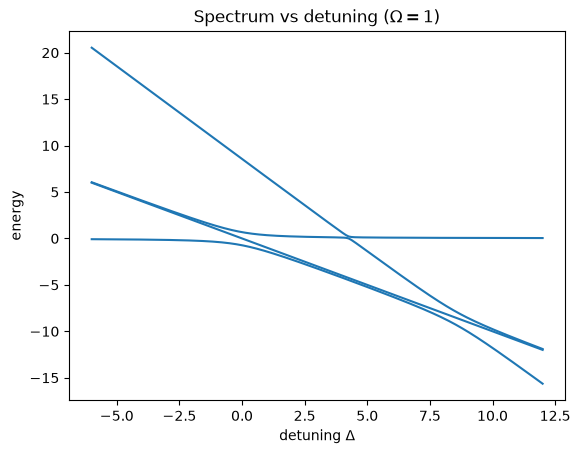

In [3]:
detunings = torch.linspace(-6, 12, 400, dtype=torch.float64)
energies = torch.linalg.eigvalsh(ham(1.0, detunings))  # (400, 4)

plt.plot(detunings, energies, color="C0")
plt.xlabel(r"detuning $\Delta$")
plt.ylabel("energy")
plt.title(r"Spectrum vs detuning ($\Omega = 1$)");

## Rydberg blockade

Driving both atoms resonantly ($\Delta = 0$) from $|00\rangle$: far apart, they behave independently and reach
$|11\rangle$. Close together, the interaction blocks double excitation. The pair then oscillates collectively between
$|00\rangle$ and $(|01\rangle + |10\rangle)/\sqrt{2}$ at the enhanced frequency $\sqrt{2}\,\Omega$.

`time_evolution` broadcasts over a tensor of times, giving every time step at once.

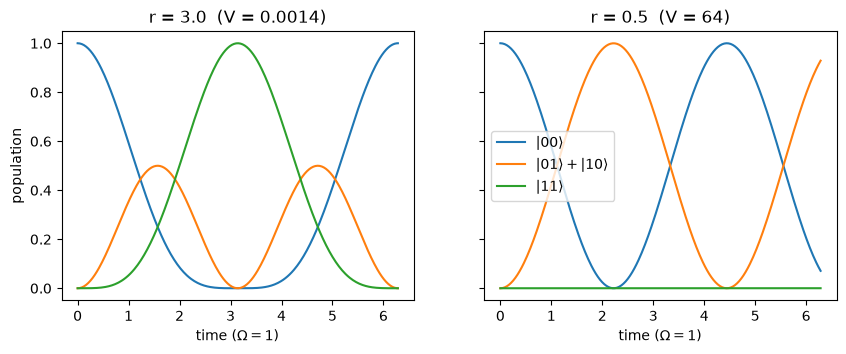

In [4]:
times = torch.linspace(0, 2 * torch.pi, 300, dtype=torch.float64)
psi0 = torch.tensor([1, 0, 0, 0], dtype=ops.DTYPE)  # |00>

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, distance in zip(axes, [3.0, 0.5]):
    h = hornbill.RydbergHamiltonian(distance=distance)(rabi=1.0, detuning=0.0)
    pops = (hornbill.time_evolution(h, times) @ psi0).abs() ** 2  # (300, 4)
    ax.plot(times, pops[:, 0], label=r"$|00\rangle$")
    ax.plot(times, pops[:, 1] + pops[:, 2], label=r"$|01\rangle + |10\rangle$")
    ax.plot(times, pops[:, 3], label=r"$|11\rangle$")
    ax.set_title(f"r = {distance}  (V = {1 / distance**6:.2g})")
    ax.set_xlabel(r"time ($\Omega = 1$)")
axes[0].set_ylabel("population")
axes[1].legend();

## A piecewise-constant pulse

`Pulse(n, time)` splits the duration into `n` equal steps and holds one trainable amplitude per step per control channel
in `pulse.params` (shape `(n, 2)`). The columns line up with `ham.controls = [rabi_op, detuning_op]`, so during step $j$

$$ H_j = V n_1 n_2 + \Omega_j\, \text{rabi\_op} + \Delta_j\, \text{detuning\_op}, $$

and `pulse.unitary(ham.controls, ham.drift)` returns $U = e^{-iH_{n-1}\,dt} \cdots e^{-iH_0\,dt}$.

Pulse(n=50, time=10.0, n_controls=2)
dt = 0.2
params: (50, 2)


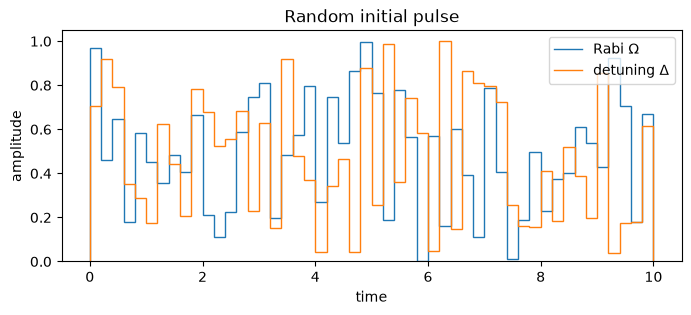

In [5]:
pulse = hornbill.Pulse(n=50, time=10.0, generator=torch.Generator().manual_seed(0))
print(pulse, f"dt = {pulse.dt}", f"params: {tuple(pulse.params.shape)}", sep="\n")


def plot_pulse(pulse, title):
    t = torch.cat([pulse.times, torch.tensor([pulse.time])])
    params = pulse.params.detach()
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.stairs(params[:, 0], t, label=r"Rabi $\Omega$")
    ax.stairs(params[:, 1], t, label=r"detuning $\Delta$")
    ax.set_xlabel("time")
    ax.set_ylabel("amplitude")
    ax.set_title(title)
    ax.legend()


plot_pulse(pulse, "Random initial pulse")

## Optimising a CZ gate

The loss is the gate infidelity between the pulse's unitary and CZ. `unitary_infidelity` ignores global phase.
Everything is differentiable, so `gradient_descent` updates `pulse.params` in place.

initial infidelity: 0.878


final infidelity:   6.42e-04


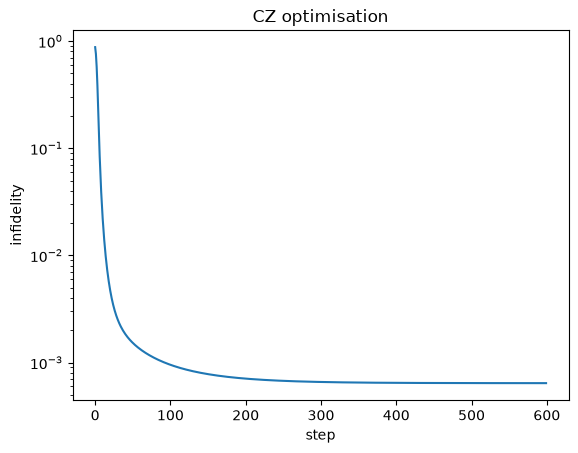

In [6]:
def loss(params):
    return hornbill.unitary_infidelity(pulse.unitary(ham.controls, ham.drift), ops.CZ)


print(f"initial infidelity: {loss(pulse.params).item():.3f}")
history = hornbill.gradient_descent(loss, [pulse.params], lr=1.0, steps=600)
print(f"final infidelity:   {history[-1]:.2e}")

plt.semilogy(history)
plt.xlabel("step")
plt.ylabel("infidelity")
plt.title("CZ optimisation");

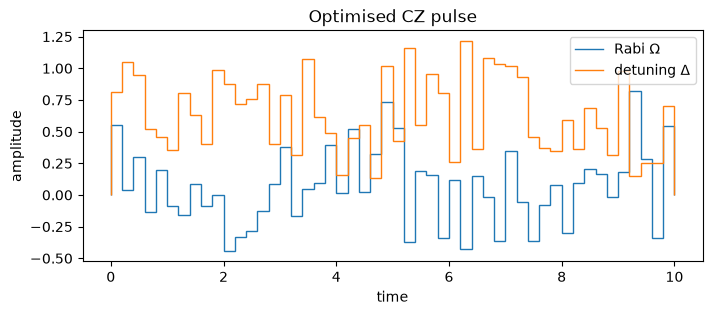

In [7]:
plot_pulse(pulse, "Optimised CZ pulse")

The final unitary, with the global phase removed, is close to $\text{diag}(1, 1, 1, -1)$:

In [8]:
u = pulse.unitary(ham.controls, ham.drift).detach()
u = u / (u[0, 0] / u[0, 0].abs())  # remove global phase
print(u.real.round(decimals=2))
print(f"distance to CZ: {hornbill.unitary_distance(u, ops.CZ).item():.3f}")

tensor([[ 1., -0., -0., -0.],
        [ 0.,  1.,  0.,  0.],
        [ 0.,  0.,  1.,  0.],
        [-0.,  0.,  0., -1.]], dtype=torch.float64)
distance to CZ: 0.018


### Why not CNOT?

Both atoms see the same global laser, so $H$ is unchanged when the atoms are swapped. Every reachable unitary therefore
commutes with SWAP. CZ does; CNOT does not, so optimising towards CNOT stalls at a large infidelity. A CNOT needs
individual addressing, or CZ followed by single-qubit Hadamards on the target.

In [9]:
for name, gate in [("CZ", ops.CZ), ("CNOT", ops.CNOT)]:
    commutes = torch.allclose(gate @ ops.SWAP, ops.SWAP @ gate)
    print(f"{name:4s} commutes with SWAP: {commutes}")

CZ   commutes with SWAP: True
CNOT commutes with SWAP: False
